# Seed variance: the noise floor for Ramen

**Why.** Candidate fixes are expected to move accuracy by about 0.3–3 pts. This notebook measures how much the *unchanged* baseline moves between seeds, so a fix is only believed when it clearly beats that spread.

**What the seed changes.** Only the order of the test stream (the DataLoader shuffle). Nothing in `methods/` or `models/` draws random numbers, and re-running a seed reproduces it exactly. NoAdapt doesn't adapt, so it must give identical results for every seed; that is checked below.

**Protocol.** Same settings as the baselines (mixed mode, batch 100, default backbones), seeds 0–4, all on RTX 3090s. Numbers from different GPU models are not comparable. Results are cached per seed in `results/`, so re-running is cheap.

**Rule for later comparisons** (PC2 handoff): a fix counts only if its gain exceeds **2 × (max − min)** of the baseline across seeds, and the fix must be run at the *same* seeds.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # one free RTX 3090; must be set before torch is imported

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ramen_analysis import make_experiment, BLUE, ORANGE, MUTED, TEXT, TEXT_2, SURFACE, _top_legend

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

In [2]:
DATASETS     = ['CIFAR10C', 'CIFAR100C']
SEEDS        = [0, 1, 2, 3, 4]   # seed 0 is already cached from the dataset notebooks
TTA_MODE     = 'mixed'
BATCH_SIZE   = 100
N_PER_DOMAIN = None              # None = whole dataset (the noise floor must be measured on full data)

## Run every seed
About 5 min per CIFAR-10-C seed and 12.5 min per CIFAR-100-C seed on a free 3090, roughly 70 min for seeds 1–4 of both datasets. Cached seeds load in seconds.

In [3]:
metrics, noadapt_acc, ramen_preds, shares, base_shares = {}, {}, {}, {}, {}

for ds in DATASETS:
    exp = make_experiment(ds, tta_mode=TTA_MODE, batch_size=BATCH_SIZE, n_per_domain=N_PER_DOMAIN).load()
    for seed in SEEDS:
        exp.seed, exp.results, exp.features = seed, {}, {}
        exp.evaluate()
        metrics[ds, seed] = exp.summary_metrics('Ramen')
        noadapt_acc[ds, seed] = exp.results['NoAdapt'].groupby('domain_idx')['correct'].mean() * 100
        ramen_preds[ds, seed] = exp.results['Ramen'].set_index(['domain_idx', 'sample_idx'])['pred'].sort_index()
        shares[ds, seed] = exp.class_shares('Ramen')
        base_shares[ds] = exp.class_shares('NoAdapt')
        print(f"{ds} seed {seed}: Ramen avg {metrics[ds, seed]['avg']:.2f}")
    del exp
    torch.cuda.empty_cache()

M = pd.DataFrame(metrics).T
M.index.names = ['dataset', 'seed']

CIFAR10C: 15 corruptions x 10000 images, 10 classes, model=clip_vitbase32, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


CIFAR10C seed 0: Ramen avg 72.61


39936


NoAdapt:   0%|          | 0/1500 [00:00<?, ?it/s]

NoAdapt:   0%|          | 1/1500 [00:01<39:49,  1.59s/it]

...

Ramen: 100%|█████████▉| 1498/1500 [09:52<00:00,  2.53it/s]

Ramen: 100%|█████████▉| 1499/1500 [09:53<00:00,  2.54it/s]

Ramen: 100%|██████████| 1500/1500 [09:53<00:00,  2.54it/s]

Ramen: 100%|██████████| 1500/1500 [09:53<00:00,  2.53it/s]

CIFAR100C seed 4: Ramen avg 46.06


## Sanity check: NoAdapt must not depend on the seed

In [4]:
for ds in DATASETS:
    accs = pd.DataFrame({s: noadapt_acc[ds, s] for s in SEEDS})
    spread = (accs.max(axis=1) - accs.min(axis=1)).max()
    print(f'{ds}: largest NoAdapt per-corruption difference across seeds = {spread:.4f} pts '
          + ('(OK)' if spread < 1e-9 else '(UNEXPECTED: check for nondeterminism)'))

CIFAR10C: largest NoAdapt per-corruption difference across seeds = 0.0000 pts (OK)
CIFAR100C: largest NoAdapt per-corruption difference across seeds = 0.0000 pts (OK)


## The noise floor
One row per metric. `min detectable` = 2 × range: the smallest gain a fix must show before it counts. Accuracy columns are in pts, `TV(pred, true)` is the total-variation distance between predicted and true class distributions, and `overshoot %` is how far a class's predicted share sits above (+) or below (−) its true share.

In [5]:
MAIN = ['avg', 'noise', 'other', 'fixed %', 'broken %', 'TV(pred, true)', 'ECE']

def noise_floor(ds, cols=None):
    m = M.loc[ds].dropna(axis=1, how='all')   # drop the other dataset's watch classes
    cols = cols or MAIN + [c for c in m.columns if c.endswith('overshoot %')]
    t = pd.DataFrame({'mean': m[cols].mean(), 'std': m[cols].std(ddof=1),
                      'min': m[cols].min(), 'max': m[cols].max()})
    t['range'] = t['max'] - t['min']
    t['min detectable (2x range)'] = 2 * t['range']
    return t.round(3)

for ds in DATASETS:
    print(f'\n{ds}  (seeds {SEEDS})')
    display(noise_floor(ds))


CIFAR10C  (seeds [0, 1, 2, 3, 4])


,mean,std,min,max,range,min detectable (2x range)
avg,72.623,0.059,72.529,72.684,0.155,0.311
noise,59.974,0.125,59.760,60.083,0.323,0.647
other,75.785,0.056,75.721,75.861,0.140,0.280
fixed %,16.881,0.039,16.824,16.921,0.097,0.193
broken %,5.614,0.042,5.567,5.665,0.099,0.197
"TV(pred, true)",0.054,0.001,0.054,0.055,0.001,0.003
ECE,8.349,0.069,8.299,8.469,0.170,0.339
deer overshoot %,28.333,0.446,27.693,28.833,1.140,2.280
frog overshoot %,-30.213,0.179,-30.453,-30.060,0.393,0.787
truck overshoot %,9.544,0.357,9.013,9.913,0.900,1.800



CIFAR100C  (seeds [0, 1, 2, 3, 4])


,mean,std,min,max,range,min detectable (2x range)
avg,46.099,0.044,46.063,46.171,0.107,0.215
noise,35.260,0.147,35.097,35.487,0.390,0.780
other,48.809,0.035,48.763,48.846,0.083,0.165
fixed %,13.547,0.032,13.515,13.593,0.078,0.156
broken %,4.544,0.033,4.518,4.599,0.081,0.163
"TV(pred, true)",0.171,0.001,0.169,0.171,0.002,0.005
ECE,9.903,0.094,9.785,10.027,0.242,0.484
oak_tree overshoot %,101.120,3.013,97.933,104.533,6.600,13.200
possum overshoot %,68.960,1.836,66.267,71.333,5.067,10.133
tractor overshoot %,73.333,2.613,70.467,77.067,6.600,13.200


Per-seed values, for the record:

In [6]:
for ds in DATASETS:
    m = M.loc[ds].dropna(axis=1, how='all')
    display(m[MAIN + [c for c in m.columns if c.endswith('overshoot %')]].round(2))

,avg,noise,other,fixed %,broken %,"TV(pred, true)",ECE,deer overshoot %,frog overshoot %,truck overshoot %
seed,,,,,,,,,,
0,72.61,60.08,75.74,16.92,5.67,0.05,8.31,27.69,-30.13,9.80
1,72.68,59.98,75.86,16.92,5.59,0.05,8.33,28.83,-30.35,9.01
2,72.65,60.03,75.81,16.87,5.57,0.05,8.30,28.37,-30.07,9.39
3,72.53,59.76,75.72,16.82,5.65,0.05,8.47,28.64,-30.06,9.91
4,72.64,60.02,75.79,16.88,5.60,0.06,8.34,28.13,-30.45,9.60


,avg,noise,other,fixed %,broken %,"TV(pred, true)",ECE,oak_tree overshoot %,possum overshoot %,tractor overshoot %
seed,,,,,,,,,,
0,46.10,35.10,48.85,13.53,4.53,0.17,9.96,104.53,68.67,70.47
1,46.17,35.49,48.84,13.59,4.52,0.17,9.79,99.80,69.67,77.07
2,46.10,35.28,48.81,13.53,4.52,0.17,9.90,104.13,71.33,74.60
3,46.06,35.17,48.79,13.57,4.60,0.17,9.85,97.93,66.27,71.47
4,46.06,35.27,48.76,13.51,4.55,0.17,10.03,99.20,68.87,73.07


## How much does each corruption move?
Dots are each seed's accuracy minus the 5-seed mean, per corruption. The number on the right is that corruption's range across seeds. Per-corruption claims need to beat these ranges, which are much larger than the average's.

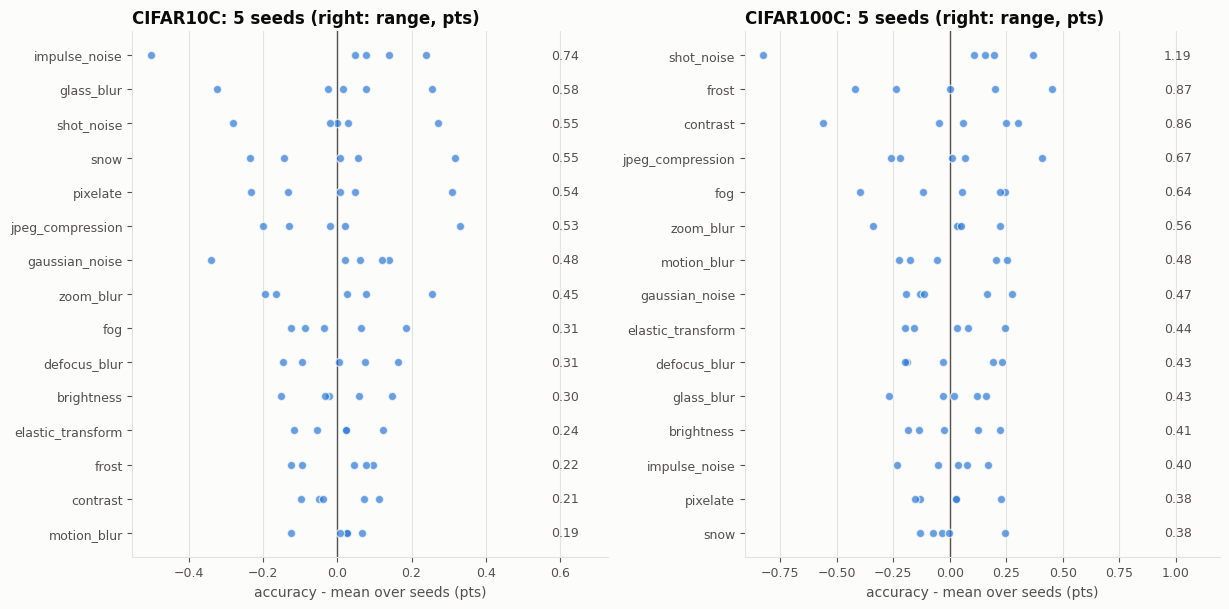

In [7]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.2 * len(DATASETS), 6.2), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    acc = M.loc[ds][[c for c in M.columns if c.startswith('acc ')]]
    acc.columns = [c[4:] for c in acc.columns]
    dev = acc - acc.mean()
    order = dev.max().sub(dev.min()).sort_values().index   # most variable on top after invert
    y = np.arange(len(order))
    for seed in dev.index:
        ax.scatter(dev.loc[seed, order], y, s=36, color=BLUE, alpha=0.7, edgecolor=SURFACE, linewidth=1, zorder=3)
    ax.axvline(0, color=TEXT_2, lw=1)
    rng = dev.max() - dev.min()
    xmax = np.abs(dev.values).max()
    for yi, c in zip(y, order):
        ax.text(xmax * 1.15, yi, f'{rng[c]:.2f}', va='center', fontsize=9, color=TEXT_2)
    ax.set_xlim(-xmax * 1.1, xmax * 1.45)
    ax.set_yticks(y, order)
    ax.grid(axis='y', visible=False)
    ax.set_xlabel('accuracy - mean over seeds (pts)')
    ax.set_title(f'{ds}: {len(dev)} seeds (right: range, pts)')
fig.tight_layout()

## Is the over-correction stable across seeds?
Predicted share vs true share per class: orange = NoAdapt (seed-independent), blue = Ramen mean, whiskers = min–max over seeds. If the whiskers are small compared with the bars, the over-correction in the research-directions file is a property of Ramen, not of seed 0. CIFAR-100-C shows the 20 classes with the largest mean Ramen bias.

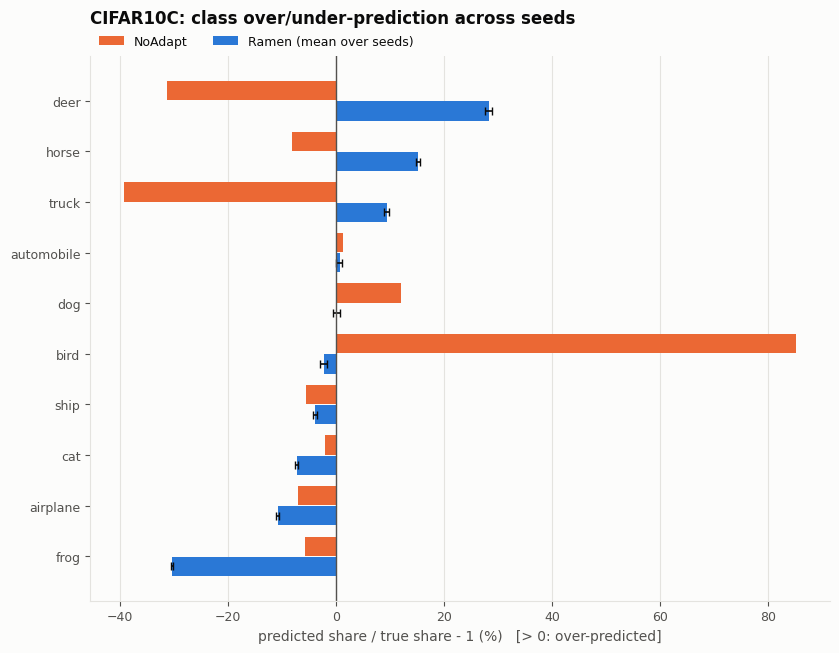

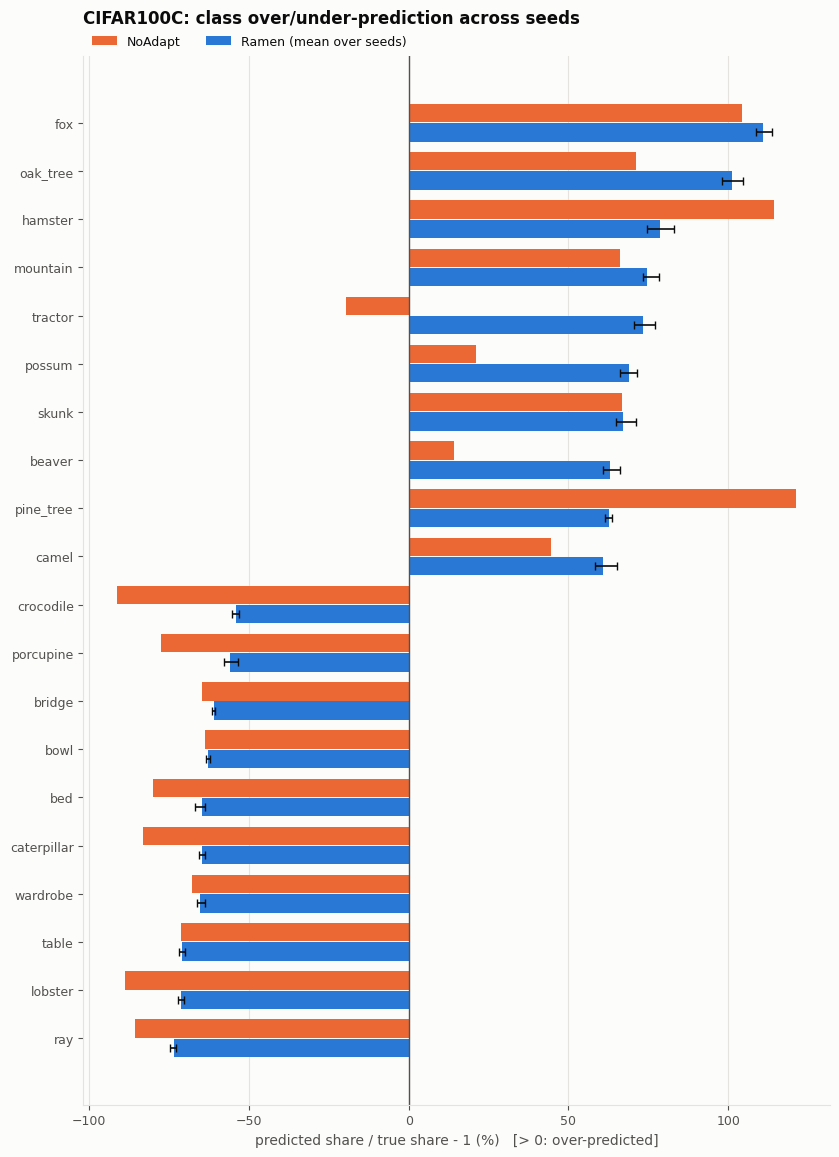

In [8]:
for ds in DATASETS:
    S = pd.DataFrame({s: shares[ds, s] for s in SEEDS})
    S = S.dropna()
    mean, lo, hi = S.mean(axis=1), S.min(axis=1), S.max(axis=1)
    base = base_shares[ds]
    rows = mean.abs().sort_values(ascending=False).index[:20]
    rows = mean[rows].sort_values(ascending=False).index
    y = np.arange(len(rows))
    fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(rows) * 1.4 + 1.6))
    ax.barh(y - 0.2, base[rows], height=0.38, color=ORANGE, label='NoAdapt')
    ax.barh(y + 0.2, mean[rows], height=0.38, color=BLUE, label='Ramen (mean over seeds)',
            xerr=np.vstack([mean[rows] - lo[rows], hi[rows] - mean[rows]]),
            error_kw=dict(ecolor=TEXT, lw=1.2, capsize=3))
    ax.axvline(0, color=TEXT_2, lw=1)
    ax.set_yticks(y, rows)
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    ax.set_xlabel('predicted share / true share - 1 (%)   [> 0: over-predicted]')
    ax.set_title(f'{ds}: class over/under-prediction across seeds', pad=24)
    _top_legend(ax)
    fig.tight_layout()
    plt.show()

## Prediction churn
Share of test samples whose Ramen prediction differs between two seeds. Even with a stable average, individual predictions can change. This bounds how much per-sample analyses (flips, failure grids, t-SNE selections) depend on the seed.

In [9]:
for ds in DATASETS:
    C = pd.DataFrame(index=SEEDS, columns=SEEDS, dtype=float)
    for a in SEEDS:
        for b in SEEDS:
            C.loc[a, b] = (ramen_preds[ds, a] != ramen_preds[ds, b]).mean() * 100
    off_diag = C.values[~np.eye(len(SEEDS), dtype=bool)]
    print(f'{ds}: churn between seed pairs {off_diag.min():.2f}-{off_diag.max():.2f}% (mean {off_diag.mean():.2f}%)')
    display(C.round(2))

CIFAR10C: churn between seed pairs 6.65-6.86% (mean 6.76%)


,0,1,2,3,4
0,0.00,6.77,6.76,6.86,6.67
1,6.77,0.00,6.69,6.86,6.65
2,6.76,6.69,0.00,6.82,6.73
3,6.86,6.86,6.82,0.00,6.82
4,6.67,6.65,6.73,6.82,0.00


CIFAR100C: churn between seed pairs 17.98-18.39% (mean 18.18%)


,0,1,2,3,4
0,0.00,18.17,18.24,18.09,17.99
1,18.17,0.00,18.39,18.36,17.98
2,18.24,18.39,0.00,18.25,18.14
3,18.09,18.36,18.25,0.00,18.15
4,17.99,17.98,18.14,18.15,0.00


## How to use this
- **Judge a fix at the same seeds** (0–4) on the same GPU model, and compare it seed by seed with the baseline. A paired difference is less noisy than comparing two means.
- **A gain counts** only above the `min detectable` value of the metric it claims to improve, on **both** datasets.
- **Per-corruption claims** need the per-corruption ranges above, not the average's.
- `exp.summary_metrics()` computes the same metrics for any run, so a fix's numbers line up with this table directly.